<a href="https://colab.research.google.com/github/Rohan181818/Statistical-and-trends-report-1/blob/main/statistical_and_trends_report.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Cell 1: Setup folders and download the official EV dataset
import os
import urllib.request

# Create folders in Colab environment
os.makedirs('data', exist_ok=True)
os.makedirs('figures', exist_ok=True)

dataset_url = "https://data.wa.gov/api/views/f6w7-q2d2/rows.csv?accessType=DOWNLOAD"
destination_file = "data/ev_data.csv"

print("Downloading Electric Vehicle Population dataset...")
urllib.request.urlretrieve(dataset_url, destination_file)
print(" Download complete: saved to 'data/ev_data.csv'")

 Download complete: saved to 'data/ev_data.csv'


In [ ]:
# Cell 2: Initial inspection of raw data
import pandas as pd

df_raw = pd.read_csv('data/ev_data.csv')

print(f"Raw Dataset Shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
print("\n--- Column Info ---")
print(df_raw.info())

print("\n--- Missing Values Count per Column ---")
print(df_raw.isnull().sum())

Raw Dataset Shape: 300142 rows, 16 columns

--- Column Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300142 entries, 0 to 300141
Data columns (total 16 columns):
 #   Column                                             Non-Null Count   Dtype  
---  ------                                             --------------   -----  
 0   VIN (1-10)                                         300142 non-null  object 
 1   County                                             300127 non-null  object 
 2   City                                               300127 non-null  object 
 3   State                                              300142 non-null  object 
 4   Postal Code                                        300127 non-null  float64
 5   Model Year                                         300142 non-null  int64  
 6   Make                                               300142 non-null  object 
 7   Model                                              300142 non-null  object 
 8   Electric V

In [ ]:
# Cell 3: Clean, standardize, filter, and export dataset (Updated & Resilient)
import numpy as np

# 1. Clean column headers by stripping any accidental whitespace
df = df_raw.copy()
df.columns = df.columns.str.strip()

# 2. Select the core analytical features needed for the plots
core_columns = ['Model Year', 'Make', 'Model', 'Electric Vehicle Type', 'Electric Range']

# Safe selection: keep only the core columns that exist in the dataset
df = df[[col for col in core_columns if col in df.columns]].copy()

# 3. Handle missing critical fields
df.dropna(subset=['Make', 'Model', 'Model Year'], inplace=True)

# 4. Standardize text and abbreviations
df['Make'] = df['Make'].astype(str).str.upper().str.strip()
df['Model'] = df['Model'].astype(str).str.upper().str.strip()

# Shorten vehicle type names for cleaner graph labels
df['Electric Vehicle Type'] = df['Electric Vehicle Type'].replace({
    'Battery Electric Vehicle (BEV)': 'BEV',
    'Plug-in Hybrid Electric Vehicle (PHEV)': 'PHEV'
})

# 5. Temporal Filtering (Focus on the Modern EV Era: 2012 to 2024)
df['Model Year'] = pd.to_numeric(df['Model Year'], errors='coerce')
df_clean = df[(df['Model Year'] >= 2012) & (df['Model Year'] <= 2024)].copy()

# 6. Save cleaned data
df_clean.to_csv('data/ev_cleaned.csv', index=False)

print(f" Data cleaning complete! Total cleaned records: {len(df_clean):,}")
display(df_clean.head())

 Data cleaning complete! Total cleaned records: 223,498


,Model Year,Make,Model,Electric Vehicle Type,Electric Range
0,2023,FORD,MUSTANG MACH-E,BEV,0.0
2,2018,TESLA,MODEL 3,BEV,215.0
3,2019,HONDA,CLARITY,PHEV,47.0
4,2024,JEEP,WRANGLER,PHEV,21.0
5,2018,TESLA,MODEL 3,BEV,215.0


/tmp/ipykernel_2581/4131358827.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=top_makes.values, y=top_makes.index, palette=palette)


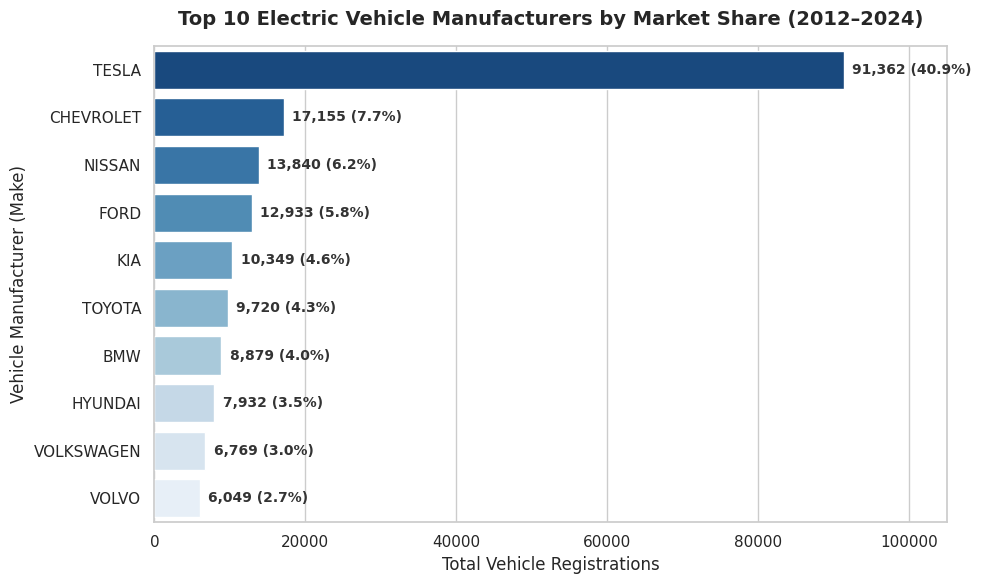

 Plot 1 saved as 'figures/plot1_top_10_manufacturers.png'


In [ ]:
# Cell 4: Plot 1 - Top 10 EV Manufacturers (Category 1: Bar Chart)
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Calculate counts and percentages
top_makes = df_clean['Make'].value_counts().head(10)
total_vehicles = len(df_clean)

palette = sns.color_palette("Blues_r", n_colors=10)
ax = sns.barplot(x=top_makes.values, y=top_makes.index, palette=palette)

# Annotate bars with counts and percentages
for i, (count, make) in enumerate(zip(top_makes.values, top_makes.index)):
    pct = (count / total_vehicles) * 100
    ax.text(count + (total_vehicles * 0.005), i, f'{count:,} ({pct:.1f}%)',
            va='center', fontsize=10, fontweight='bold', color='#333333')

plt.title('Top 10 Electric Vehicle Manufacturers by Market Share (2012–2024)', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Total Vehicle Registrations', fontsize=12)
plt.ylabel('Vehicle Manufacturer (Make)', fontsize=12)
plt.xlim(0, top_makes.values[0] * 1.15)  # Leave room for labels

plt.tight_layout()
plt.savefig('figures/plot1_top_10_manufacturers.png', dpi=300)
plt.show()
print(" Plot 1 saved as 'figures/plot1_top_10_manufacturers.png'")

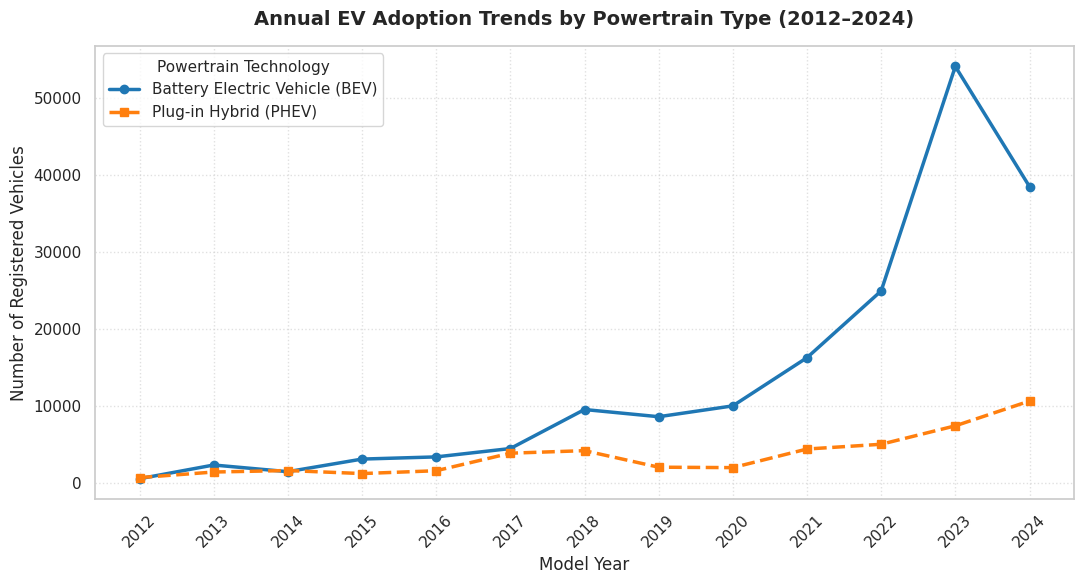

 Plot 2 saved as 'figures/plot2_adoption_trends.png'


In [ ]:
# Cell 5: Plot 2 - Adoption Trend Over Time (Category 2: Line Graph)
plt.figure(figsize=(11, 6))

# Aggregate by Model Year and Vehicle Type
trend_df = df_clean.groupby(['Model Year', 'Electric Vehicle Type']).size().unstack(fill_value=0)

plt.plot(trend_df.index, trend_df['BEV'], marker='o', linewidth=2.5, color='#1f77b4', label='Battery Electric Vehicle (BEV)')
plt.plot(trend_df.index, trend_df['PHEV'], marker='s', linewidth=2.5, color='#ff7f0e', linestyle='--', label='Plug-in Hybrid (PHEV)')

# Highlight peak and trends
plt.title('Annual EV Adoption Trends by Powertrain Type (2012–2024)', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Model Year', fontsize=12)
plt.ylabel('Number of Registered Vehicles', fontsize=12)
plt.xticks(trend_df.index, rotation=45)
plt.legend(title='Powertrain Technology', fontsize=11, title_fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('figures/plot2_adoption_trends.png', dpi=300)
plt.show()
print(" Plot 2 saved as 'figures/plot2_adoption_trends.png'")

/tmp/ipykernel_2581/2294333002.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


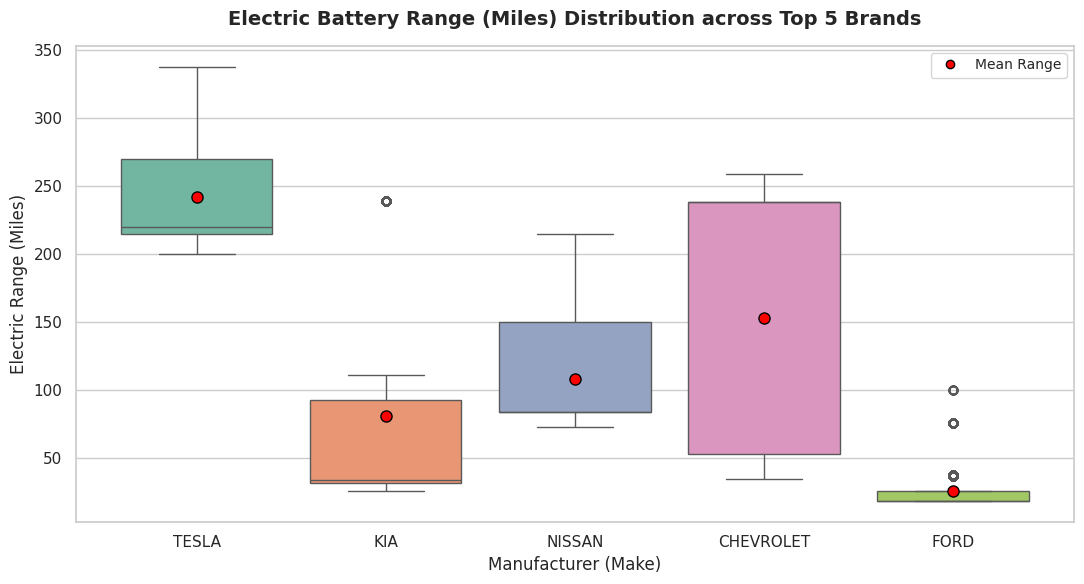

 Plot 3 saved as 'figures/plot3_electric_range_boxplot.png'


In [ ]:
# Cell 6: Plot 3 - Electric Range Distribution by Brand (Category 3: Box Plot)
plt.figure(figsize=(11, 6))

# Note: Filter Electric Range > 0 (excludes non-reported/untested EPA models to show true battery capability)
top_5_makes = df_clean['Make'].value_counts().head(5).index
range_subset = df_clean[(df_clean['Make'].isin(top_5_makes)) & (df_clean['Electric Range'] > 0)]

sns.boxplot(
    data=range_subset,
    x='Make',
    y='Electric Range',
    palette="Set2",
    showmeans=True,
    meanprops={"marker":"o", "markerfacecolor":"red", "markeredgecolor":"black", "markersize":"8"}
)

plt.title('Electric Battery Range (Miles) Distribution across Top 5 Brands', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Manufacturer (Make)', fontsize=12)
plt.ylabel('Electric Range (Miles)', fontsize=12)

# Legend note for the red dot mean indicator
plt.plot([], [], marker='o', color='red', markeredgecolor='black', linestyle='None', label='Mean Range')
plt.legend(loc='upper right', fontsize=10)

plt.tight_layout()
plt.savefig('figures/plot3_electric_range_boxplot.png', dpi=300)
plt.show()
print(" Plot 3 saved as 'figures/plot3_electric_range_boxplot.png'")

In [ ]:
# Cell 7: Generate Key Statistics for Writing your Report
print("=== STATISTICAL SUMMARY FOR REPORT ===")
print(f"Total Analyzed Vehicles: {len(df_clean):,}")
print(f"BEV Count: {len(df_clean[df_clean['Electric Vehicle Type'] == 'BEV']):,} ({(len(df_clean[df_clean['Electric Vehicle Type'] == 'BEV'])/len(df_clean))*100:.1f}%)")
print(f"PHEV Count: {len(df_clean[df_clean['Electric Vehicle Type'] == 'PHEV']):,} ({(len(df_clean[df_clean['Electric Vehicle Type'] == 'PHEV'])/len(df_clean))*100:.1f}%)")

print("\n--- Top Brand Market Share ---")
top_3 = df_clean['Make'].value_counts().head(3)
for make, count in top_3.items():
    print(f"{make}: {count:,} vehicles ({count/len(df_clean)*100:.1f}%)")

print("\n--- Electric Range Statistics (where Range > 0) ---")
tested_range = df_clean[df_clean['Electric Range'] > 0]['Electric Range']
print(f"Mean Range:   {tested_range.mean():.1f} miles")
print(f"Median Range: {tested_range.median():.1f} miles")
print(f"IQR (Q1-Q3):  {tested_range.quantile(0.25):.1f} - {tested_range.quantile(0.75):.1f} miles")
print(f"Max Range:    {tested_range.max():.1f} miles")

=== STATISTICAL SUMMARY FOR REPORT ===
Total Analyzed Vehicles: 223,498
BEV Count: 177,257 (79.3%)
PHEV Count: 46,241 (20.7%)

--- Top Brand Market Share ---
TESLA: 91,362 vehicles (40.9%)
CHEVROLET: 17,155 vehicles (7.7%)
NISSAN: 13,840 vehicles (6.2%)

--- Electric Range Statistics (where Range > 0) ---
Mean Range:   114.5 miles
Median Range: 72.0 miles
IQR (Q1-Q3):  30.0 - 215.0 miles
Max Range:    337.0 miles


In [ ]:
# Cell 8: Helper to download all 3 generated figures directly from Colab
from google.colab import files

files.download('figures/plot1_top_10_manufacturers.png')
files.download('figures/plot2_adoption_trends.png')
files.download('figures/plot3_electric_range_boxplot.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>